# **Image Transformation**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.util import invert
from skimage.color import rgb2gray
from skimage.filters import sobel, gaussian
from skimage.exposure import rescale_intensity
from skimage import io, data, img_as_ubyte, img_as_float

**1 Image Representation**

[[ 5  4  5  6  5  5  6  5  5  6]
 [ 4  5  5  6  5  5  4  5  5  8]
 [ 6  5  5  6  6  4  6  5  6 10]
 [ 5  5  5  5  6  4  5  5  5  9]
 [ 4  5  5  5  5  5  5  5  6  8]
 [ 4  5  6  5  5  5  7  7  6  7]
 [ 4  5  6  5  6  8 14  8  5  5]
 [ 5  5  5  6  9 15 17  9  5  4]
 [ 5  6  8 11 16 18 15 10  5  5]
 [ 7 11 15 17 18 19 16  9  4  5]]


array([[200, 200, 200, ..., 189, 190, 190],
       [200, 199, 199, ..., 190, 190, 190],
       [199, 199, 199, ..., 190, 190, 190],
       ...,
       [ 25,  25,  27, ..., 139, 122, 147],
       [ 25,  25,  26, ..., 158, 141, 168],
       [ 25,  25,  27, ..., 151, 152, 149]], dtype=uint8)
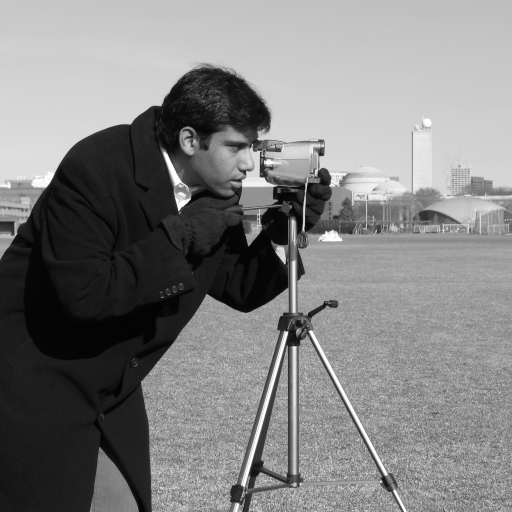

In [9]:
im_camera = data.camera()
print(im_camera[250:260,250:260])
im_camera

array([[171, 159, 128, ..., 117, 108,  87],
       [171, 161, 158, ..., 122,  95,  86],
       [195, 168, 133, ..., 106, 114, 123],
       ...,
       [ 25,  29,  70, ...,  64,  92, 139],
       [ 34,  76,  97, ...,  69,  97, 140],
       [ 60, 105, 114, ...,  83, 112, 158]], dtype=uint8)
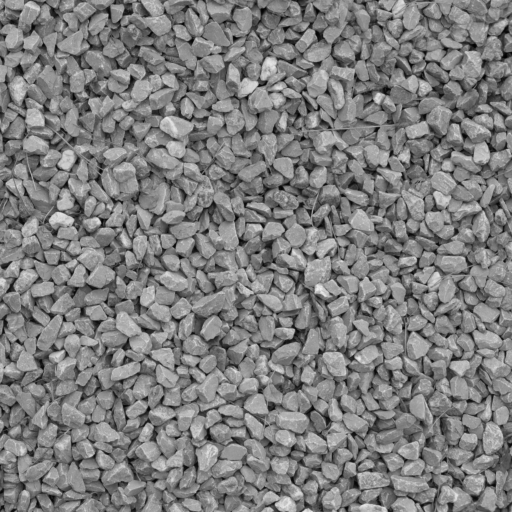

In [8]:
im_gravel = data.gravel()
im_gravel

*#* Multiply

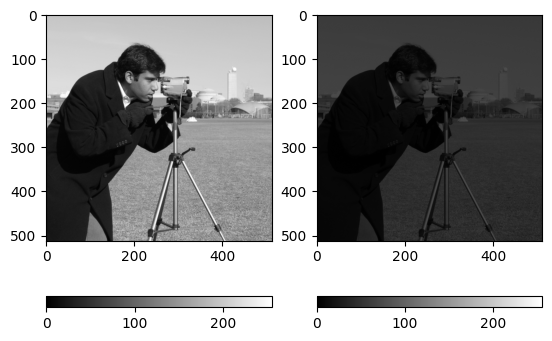

In [ ]:
fig = plt.figure()
ax = fig.add_subplot(1, 2, 1)
p = plt.imshow(im, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

ax = fig.add_subplot(1, 2, 2)
p = plt.imshow(imf, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

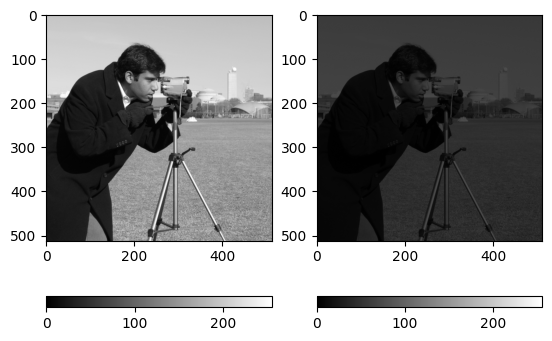

In [7]:
imf = 0.3 * im_camera
imf = imf.astype(np.uint8)

fig = plt.figure()

ax = fig.add_subplot(1, 2, 1)
plt.imshow(im_camera, cmap = 'gray')
plt.colorbar(orientation = 'horizontal')
plt.clim(0, 255)

ax = fig.add_subplot(1, 2, 2)
plt.imshow(imf, cmap = 'gray')
plt.colorbar(orientation = 'horizontal')
plt.clim(0, 255)

**2 Mix**

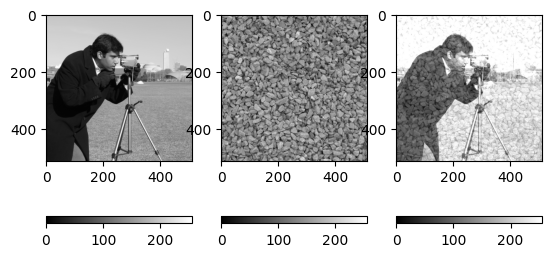

In [10]:
im_mix = im_camera.astype(float) + 0.5 * im_gravel.astype(float)

fig = plt.figure()
ax = fig.add_subplot(1, 3, 1)
p = plt.imshow(im_camera, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

ax = fig.add_subplot(1, 3, 2)
p = plt.imshow(im_gravel, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

ax = fig.add_subplot(1, 3, 3)
p = plt.imshow(im_mix, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

**3 Addition**

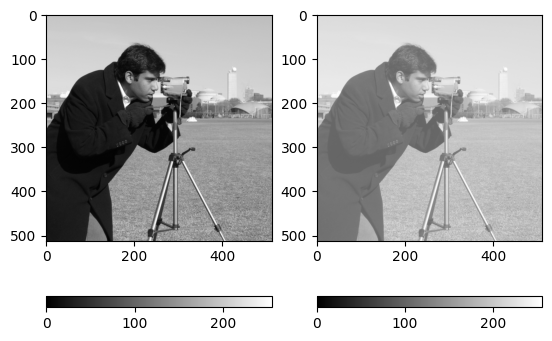

In [11]:
c = 100
imf = (rescale_intensity(im_camera, out_range=(c, 255))).astype(np.uint8) #maps the intensity from 100 to 255

fig = plt.figure()
ax = fig.add_subplot(1, 2, 1)
p = plt.imshow(im_camera, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

ax = fig.add_subplot(1, 2, 2)
p = plt.imshow(imf, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

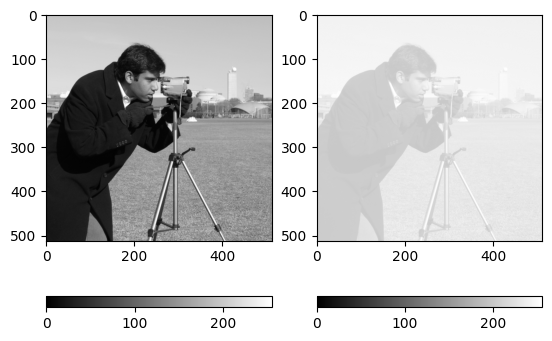

In [13]:
c = 200
imf = (rescale_intensity(im_camera, out_range=(c, 255))).astype(np.uint8)

fig = plt.figure()
ax = fig.add_subplot(1, 2, 1)
p = plt.imshow(im_camera, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

ax = fig.add_subplot(1, 2, 2)
p = plt.imshow(imf, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

**4 Blending**

In [14]:
import inspect

print(inspect.getsource(sobel))

def sobel(image, mask=None, *, axis=None, mode='reflect', cval=0.0):
    """Find edges in an image using the Sobel filter.

    Parameters
    ----------
    image : array
        The input image.
    mask : array of bool, optional
        Clip the output image to this mask. (Values where mask=0 will be set
        to 0.)
    axis : int or sequence of int, optional
        Compute the edge filter along this axis. If not provided, the edge
        magnitude is computed. This is defined as::

            sobel_mag = np.sqrt(sum([sobel(image, axis=i)**2
                                     for i in range(image.ndim)]) / image.ndim)

        The magnitude is also computed if axis is a sequence.
    mode : str or sequence of str, optional
        The boundary mode for the convolution. See `scipy.ndimage.convolve`
        for a description of the modes. This can be either a single boundary
        mode or one boundary mode per axis.
    cval : float, optional
        When `mode` is ``'consta

In [15]:
im_sobel = sobel(im_camera) #Sobel-Feldman operator for egde detection

array([[9.80392157e-04, 2.19222351e-03, 2.19222351e-03, ...,
        2.94117647e-03, 2.19222351e-03, 0.00000000e+00],
       [3.10027222e-03, 3.10027222e-03, 2.94117647e-03, ...,
        2.19222351e-03, 9.80392157e-04, 0.00000000e+00],
       [9.80392157e-04, 1.96078431e-03, 1.38648388e-03, ...,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       ...,
       [9.80392157e-04, 4.38444701e-03, 3.53485419e-03, ...,
        9.19741618e-02, 2.69206475e-02, 6.44752276e-02],
       [2.45326947e-18, 4.15945165e-03, 2.19222351e-03, ...,
        3.28687345e-02, 5.43742142e-02, 5.82983088e-02],
       [2.45326947e-18, 4.90196078e-03, 2.19222351e-03, ...,
        1.80775382e-02, 3.92156863e-03, 3.42436259e-02]])

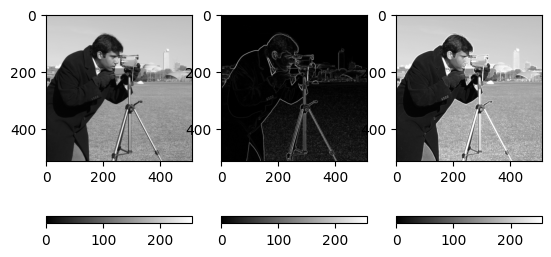

In [21]:
im_sr = rescale_intensity(im_sobel, out_range=(0, 255))
imf = im_camera + im_sr

fig = plt.figure()
ax = fig.add_subplot(1, 3, 1)
plt.imshow(im_camera, cmap = 'gray')
plt.colorbar(orientation = 'horizontal')
plt.clim(0, 255)

ax = fig.add_subplot(1, 3, 2)
p = plt.imshow(im_sr, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

ax = fig.add_subplot(1, 3, 3)
p = plt.imshow(imf, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

(array([[487.,  14.,   6., ...,   0.,   0.,   0.],
        [484.,  15.,   8., ...,   0.,   0.,   0.],
        [485.,  12.,   9., ...,   0.,   0.,   0.],
        ...,
        [448.,  51.,   9., ...,   0.,   0.,   0.],
        [459.,  44.,   8., ...,   0.,   0.,   0.],
        [453.,  49.,   8., ...,   0.,   0.,   0.]]),
 array([  0. ,  25.5,  51. ,  76.5, 102. , 127.5, 153. , 178.5, 204. ,
        229.5, 255. ]),
 <a list of 512 BarContainer objects>)

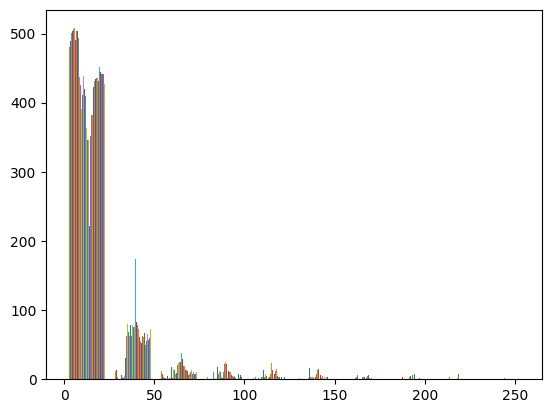

In [24]:
plt.hist(im_sr)

(array([[251.,   9.,   1., ...,   0.,   0.,   0.],
        [252.,   8.,   2., ...,   0.,   0.,   0.],
        [253.,   9.,   2., ...,   0.,   0.,   0.],
        ...,
        [  0.,   0.,  22., ...,   0.,   0.,   0.],
        [  0.,   0.,  25., ...,   0.,   0.,   0.],
        [  0.,   0.,  28., ...,   0.,   0.,   0.]]),
 array([  2.38772386,  47.0197878 ,  91.65185174, 136.28391568,
        180.91597962, 225.54804356, 270.1801075 , 314.81217144,
        359.44423538, 404.07629932, 448.70836326]),
 <a list of 512 BarContainer objects>)

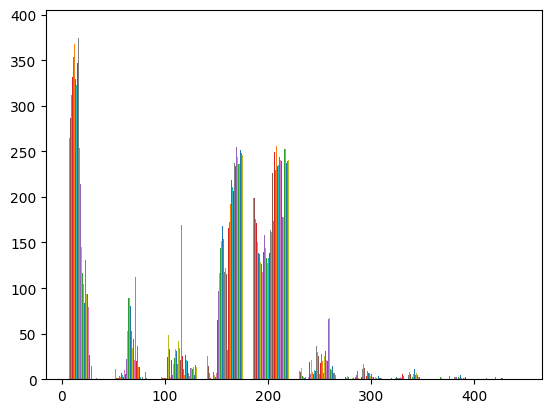

In [25]:
plt.hist(imf)

*#* Subtraction

In [35]:
im0 = img_as_float(data.camera())
im1 = gaussian(im0, sigma=10)/2
ims = im0 - im1
ims[ims<0] = 0

print(im0.dtype)
print(im1.dtype)
print(ims.dtype)

float64
float64
float64


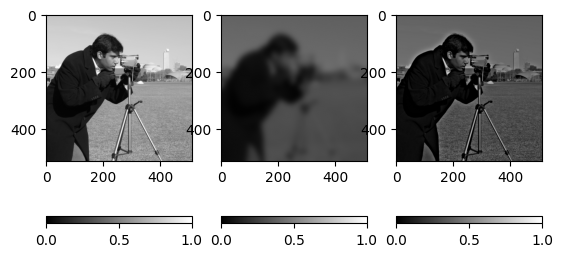

In [32]:
fig = plt.figure()

ax = fig.add_subplot(1, 3, 1)
p = plt.imshow(im0, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 1)

ax = fig.add_subplot(1, 3, 2)
p = plt.imshow(im1, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 1)

ax = fig.add_subplot(1, 3, 3)
p = plt.imshow(ims, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 1)

**5 Subtraction - move**

In [37]:
im0, im1, _ = data.stereo_motorcycle()
im0 = rgb2gray(im0)
im1 = rgb2gray(im1)
ims = np.abs(im0 - im1)

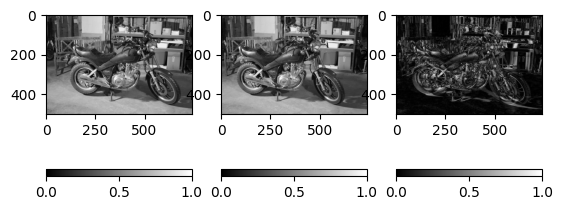

In [38]:
fig = plt.figure()
ax = fig.add_subplot(1, 3, 1)
p = plt.imshow(im0, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 1)

ax = fig.add_subplot(1, 3, 2)
p = plt.imshow(im1, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 1)

ax = fig.add_subplot(1, 3, 3)
p = plt.imshow(ims, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 1)

In [39]:
im0, im1, _ = data.stereo_motorcycle()
ims = np.abs(im0 - im1)

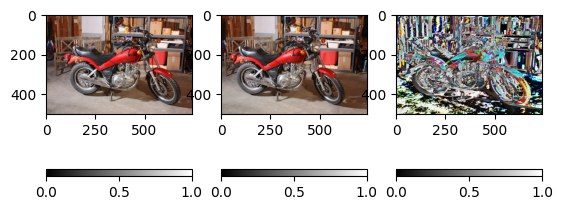

In [40]:
fig = plt.figure()
ax = fig.add_subplot(1, 3, 1)
p = plt.imshow(im0, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 1)

ax = fig.add_subplot(1, 3, 2)
p = plt.imshow(im1, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 1)

ax = fig.add_subplot(1, 3, 3)
p = plt.imshow(ims, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 1)

**6 Division**

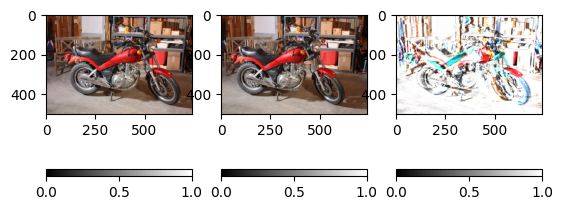

In [42]:
im0 = img_as_float(im0)
im1 = img_as_float(im1)

imd = np.zeros_like(im0)
imd[im1!=0] = im0[im1!=0] / im1[im1!=0]

#plot
fig = plt.figure()
ax = fig.add_subplot(1, 3, 1)
p = plt.imshow(im0, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 1)

ax = fig.add_subplot(1, 3, 2)
p = plt.imshow(im1, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 1)

ax = fig.add_subplot(1, 3, 3)
p = plt.imshow(imd, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 1)

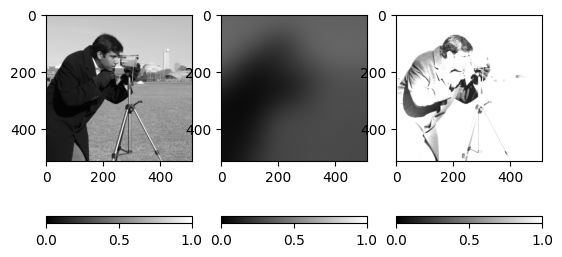

In [ ]:
im0 = img_as_float(data.camera())
im1 = gaussian(im0, sigma=50)/2
imd = np.zeros_like(im0)
imd[im1!=0] = im0[im1!=0] / im1[im1!=0]

fig = plt.figure()
ax = fig.add_subplot(1, 3, 1)
p = plt.imshow(im0, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 1)

ax = fig.add_subplot(1, 3, 2)
p = plt.imshow(im1, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 1)

ax = fig.add_subplot(1, 3, 3)
p = plt.imshow(imd, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 1)

**7 Mutliplication**

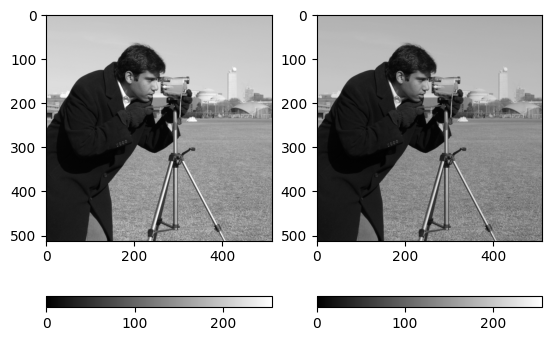

In [47]:
im = data.camera()
imm = 0.3 * im
imm = 3 * imm
imm = imm.astype(np.uint8)

fig = plt.figure()
ax = fig.add_subplot(1, 2, 1)
p = plt.imshow(im, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

ax = fig.add_subplot(1, 2, 2)
p = plt.imshow(imm, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

*#*  NOT

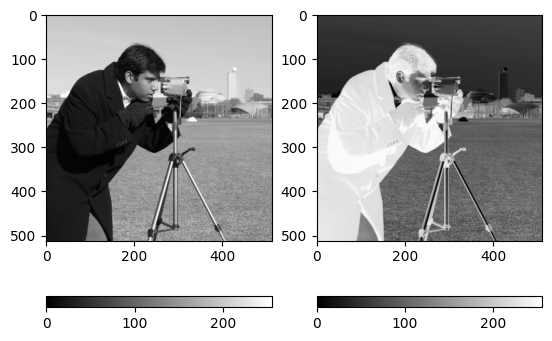

In [48]:
im = data.camera()
imn = invert(im)

fig = plt.figure()
ax = fig.add_subplot(1, 2, 1)
p = plt.imshow(im, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

ax = fig.add_subplot(1, 2, 2)
p = plt.imshow(imn, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

**8 AND**

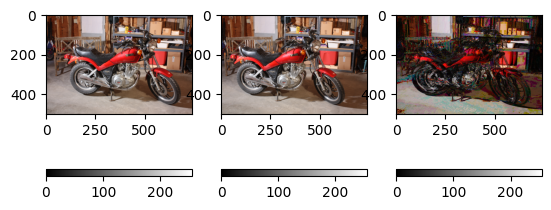

In [50]:
im0 = img_as_ubyte(im0)
im1 = img_as_ubyte(im1)

im = np.bitwise_and(im0, im1)

fig = plt.figure()
ax = fig.add_subplot(1, 3, 1)
p = plt.imshow(im0, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

ax = fig.add_subplot(1, 3, 2)
p = plt.imshow(im1, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

ax = fig.add_subplot(1, 3, 3)
p = plt.imshow(im, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

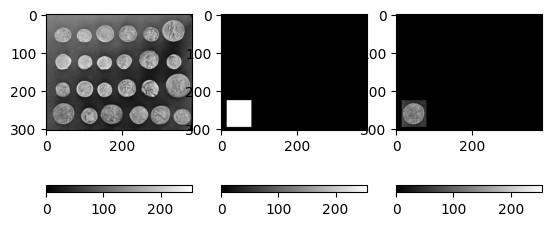

In [51]:
im = data.coins()

imm = np.zeros_like(im)

imm[225:295,15:80] = 255
ima = im.copy()
ima[imm==0] = 0

fig = plt.figure()
ax = fig.add_subplot(1, 3, 1)
p = plt.imshow(im, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

ax = fig.add_subplot(1, 3, 2)
p = plt.imshow(imm, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

ax = fig.add_subplot(1, 3, 3)
p = plt.imshow(ima, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

**9 OR**

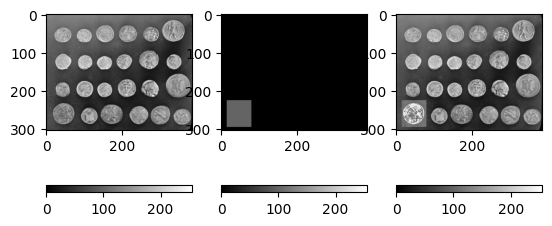

In [52]:
im = data.coins()
imm = np.zeros_like(im)
imm[225:295,15:80] = 100
imor = np.bitwise_or(im, imm)

fig = plt.figure()
ax = fig.add_subplot(1, 3, 1)
p = plt.imshow(im, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

ax = fig.add_subplot(1, 3, 2)
p = plt.imshow(imm, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

ax = fig.add_subplot(1, 3, 3)
p = plt.imshow(imor, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

**10 XOR**

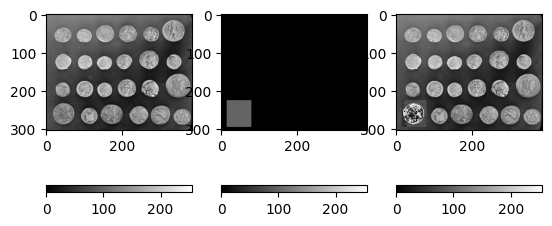

In [53]:
im = data.coins()
imm = np.zeros_like(im)
imm[225:295,15:80] = 100
imxor = np.bitwise_xor(im, imm)

fig = plt.figure()
ax = fig.add_subplot(1, 3, 1)
p = plt.imshow(im, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

ax = fig.add_subplot(1, 3, 2)
p = plt.imshow(imm, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

ax = fig.add_subplot(1, 3, 3)
p = plt.imshow(imxor, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)